# Kilonova detector observations with X-shooter

This companion to `01_Kilonovae.ipynb` uses the same Kasen models, distance, phase, and host scene. It simulates VLT UT3 / Paranal observations in the simultaneous UVB, VIS, and NIR arms, producing their native full science frames with configurable CCD on-chip binning.

Use the `xshooter` branches and the exact ScopeSim/IRDB revisions in `env/zshooter-stack.toml`. Read [the model notes](../docs/xshooter.md) and [the shared-physics evaluation](../docs/xshooter-validation.md) before quantitative comparisons.

These images compare predicted observations under the stated instrument models. Agreement with X-shooter measurements can test shared photon accounting, slit illumination, detector mapping, and noise only where those calculations and their inputs have been tested independently. The optical response and slit-resolution fits are calibration inputs, so agreement with those same inputs is not independent validation. They cannot validate ZShooter's still-unknown optical efficiencies. The separate `fidelity-candidates` branches are experimental and are not selected by this notebook.

In [1]:
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.table import Table
from astropy.visualization import simple_norm
import scopesim as sim
import scopesim_templates as sim_tp
from skycalc_ipy.core import ESOQueryBase
from zs_scopesim_tools.helpers import configure_irdb_path, make_local_output_dir, set_scopesim_log_level
from zs_scopesim_tools.sources import transient, kilonova_spectra

configure_irdb_path()
set_scopesim_log_level('warning')
ESOQueryBase.REQUEST_TIMEOUT = 120  # A full-band SkyCalc request can exceed its 2 s library default.
output_dir = make_local_output_dir('xshooter_kilonova')

The common scene parameters below match the original notebook. Keep these, seeing, airmass, and accumulated integration time the same when comparing instruments. Telescope collecting area and throughput remain those of each configured instrument. The host is displaced by the original 10.5 arcsec; no new source normalization is introduced.

In [2]:
redshift = 0.0098
phase = 1.5  # rest-frame days, as in the source notebook
host_mag = 14
source_pixel_scale = 0.01
model_files = ['knova_d1_n10_m0.025_vk0.30_Xlan1e-4.0.h5', 'knova_d1_n10_m0.040_vk0.15_Xlan1e-1.5.h5']

host = sim_tp.galaxy(sed='brown/NGC3870', z=redshift, amplitude=host_mag, pixel_scale=source_pixel_scale, r_eff=2.5, n=1., ellip=0.3, theta=90, extend=5)
host.shift(dy=10.5*u.arcsec)
spectra = kilonova_spectra(model_files, phases=[phase], redshift=redshift, combine_models=True)
source = host + transient(x=0, y=0, spextrum_template=spectra[phase], name=f'KN {phase}d')

CCD `binx` and `biny` refer to FITS columns (spatial) and rows (dispersion). Supported settings are `(1, 1)`, `(1, 2)`, and `(2, 2)`; the NIR detector is unbinned. `slow` means the standard 100 kHz high-gain CCD mode, and `fast` the 400 kHz low-gain mode. The current NIR JH slit names are `0.6JH` and `0.9JH`. Seeing is specified at zenith and 500 nm; the model applies its wavelength and airmass dependence.

A CCD output sums NDIT exposures. A NIR output averages NDIT ramps, so its count scale is one DIT while its noise decreases with NDIT. Compare total exposure as `DIT * NDIT`, and account for this count convention before comparing image values. The default 300 s / NDIT=1 avoids that distinction.

The full-band calculation samples 43 echelle orders and can take several minutes with substantial memory use.

In [3]:
properties = {
    '!OBS.object': f'Kilonova {phase}d',
    '!OBS.airmass': 1.3,
    '!OBS.seeing': 0.7,
    '!ATMO.pwv': 2.5,
    '!ATMO.moon_sun_sep': 0,
    '!INST.uvb_curr_slit': '1.0',
    '!INST.vis_curr_slit': '0.9',
    '!INST.nir_curr_slit': '0.9',
    '!OBS.dit_uvb': 300., '!OBS.ndit_uvb': 1,
    '!OBS.dit_vis': 300., '!OBS.ndit_vis': 1,
    '!OBS.dit_nir': 300., '!OBS.ndit_nir': 1,
    '!DET.binx_uvb': 1, '!DET.biny_uvb': 1,
    '!DET.binx_vis': 1, '!DET.biny_vis': 1,
    '!DET.readout_mode_uvb': 'slow',
    '!DET.readout_mode_vis': 'slow',
}
cmds = sim.UserCommands(use_instrument='XSHOOTER', set_modes=['SPEC'], properties=properties)
train = sim.OpticalTrain(cmds)

py.warnings - WARNING: /Users/jibailey/src/scopesim/scopesim/effects/spectral_trace_list.py:170: DeprecationWarning: The fov_grid method is deprecated and will be removed in a future release.
  fov = thetrace.fov_grid()



In [4]:
train.observe(source)
readouts = train.readout()

rows = []
for hdul in readouts:
    header = hdul[1].header
    arm = header['ARM']
    path = output_dir / f'kilonova_{phase:g}d_{arm.lower()}.fits'
    hdul.writeto(path, overwrite=True)
    slit_y = train['slits'].wheel_effects[header['DET_ID']].current_slit.table['y'].quantity
    slit_width = (slit_y.max() - slit_y.min()).to_value(u.arcsec)
    rows.append((arm, hdul[1].data.shape, slit_width, header['DIT'], header['NDIT'], header['EXPTIME'], header['GAIN'], header['COMBINE']))
Table(rows=rows, names=['arm', 'shape_yx', 'slit_arcsec', 'dit_s', 'ndit', 'total_integration_s', 'gain_e_per_adu', 'combination'])

py.warnings - WARNING: /Users/jibailey/src/scopesim/scopesim/effects/spectral_trace_list.py:212: DeprecationWarning: The fov_grid method is deprecated and will be removed in a future release.
  vol = spt.fov_grid()



 FOVs:   0%|          | 0/43 [00:00<?, ?it/s]

 FOV effects:   0%|          | 0/6 [00:00<?, ?it/s]

 FOV effects:   0%|          | 0/6 [00:00<?, ?it/s]

 FOV effects:   0%|          | 0/6 [00:00<?, ?it/s]

...

 FOV effects:   0%|          | 0/6 [00:00<?, ?it/s]

 FOV effects:   0%|          | 0/6 [00:00<?, ?it/s]

 FOV effects:   0%|          | 0/6 [00:00<?, ?it/s]

 FOV effects:   0%|          | 0/6 [00:00<?, ?it/s]

arm,shape_yx,slit_arcsec,dit_s,ndit,total_integration_s,gain_e_per_adu,combination
str3,int64[2],float64,float64,int64,float64,float64,str7
UVB,3000 .. 2048,1.0,300.0,1,300.0,0.63,sum
VIS,4000 .. 2048,0.9,300.0,1,300.0,0.64,sum
NIR,1100 .. 2048,0.9,300.0,1,300.0,2.29,average


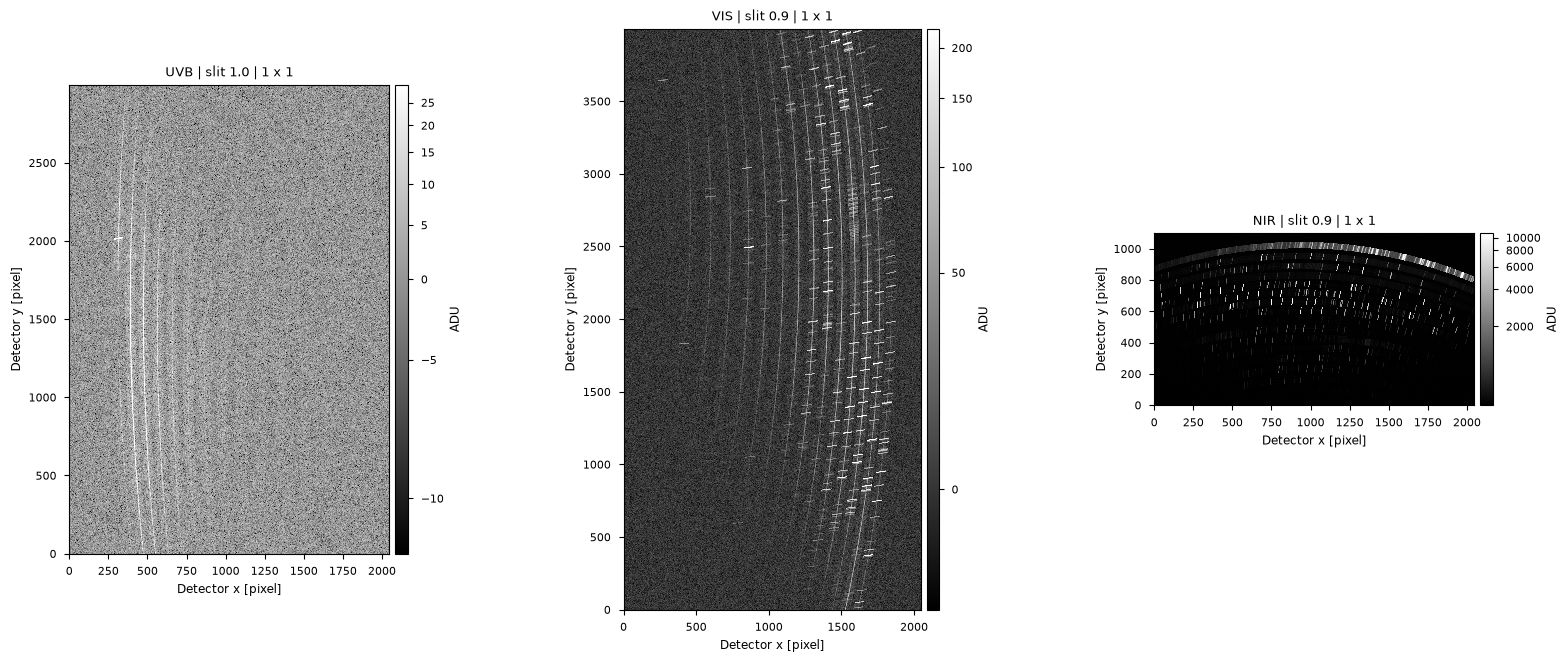

In [7]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, axes = plt.subplots(1, 3, figsize=(16, 7))
fig.subplots_adjust(left=0.05, right=0.94, bottom=0.1, top=0.93, wspace=0.6)
for ax, hdul in zip(axes, readouts):
    data, header = hdul[1].data, hdul[1].header
    norm = simple_norm(data, stretch='asinh', percent=99.8)
    image = ax.imshow(data, origin='lower', cmap='gray', norm=norm, interpolation='nearest')
    ax.set_title(f"{header['ARM']} | slit {header['SLIT']} | {header['BINX']} x {header['BINY']}")
    ax.set_xlabel('Detector x [pixel]')
    ax.set_ylabel('Detector y [pixel]')
    divider = make_axes_locatable(ax)
    colorbar_ax = divider.append_axes('right', size='4%', pad=0.06)
    fig.colorbar(image, cax=colorbar_ax, label='ADU')
fig.savefig(output_dir / 'native_frames.png', dpi=150)
plt.show()

Each image has its own display stretch. Use the FITS arrays and exposure/gain headers for numerical comparisons, not the displayed brightness. The native `D` WCS describes physical focal-plane coordinates; an echelle image does not have a single linear wavelength axis. This notebook ends at detector products; extraction and a common-resolution comparison are separate work.

For a different atmosphere, change the properties before constructing the optical train. A precomputed ESO SkyCalc FITS file can be selected with `!ATMO.local_sky_file`; its conditions must match the observation. The optical ADC approximation assumes ideal correction; NIR atmospheric dispersion is active.

The frozen optical response comes from January 2024. An independent ESO QC sample with 27 observations per arm from August–September 2026 has optical median efficiencies within 3% of that epoch in the monitored intervals, with appreciable night-to-night scatter. None of these observations is flagged photometric. The measurements do not establish accuracy outside the intervals, for NIR throughput, for slit losses, or for the host-galaxy illumination in this scene. The calibration is held fixed during engine comparisons; no throughput adjustment is used to hide numerical errors.